# Spiking Neural Networks
This notebook demonstrates a simple Leaky Integrate-and-Fire (LIF) network using Brian2.

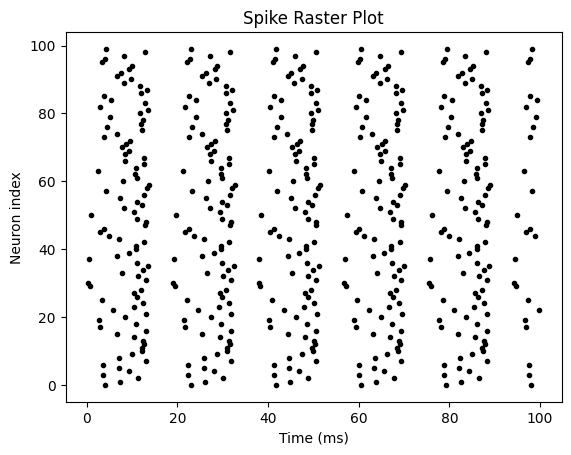

In [1]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

N = 100
tau = 10*ms
v0 = -65*mV
v_th = -50*mV
v_reset = -65*mV
I_val = 20*mV

eqs = """
dv/dt = (v0 - v + I_val) / tau : volt (unless refractory)
"""

G = NeuronGroup(N, eqs, threshold='v>v_th', reset='v=v_reset', refractory=5*ms, method='exact')
G.v = v0 + rand(N) * 15 * mV

M = SpikeMonitor(G)
run(100*ms)

plt.plot(M.t/ms, M.i, '.k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Spike Raster Plot')
plt.show()